# Тема 3. Условная вероятность
---
Возьмём реальные данные о гонках Формулы-1 за 2023 год из набора Jolpica F1. В таблице: гонка, пилот, команда, место на старте и место на финише.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import requests

### Загружаем данные

In [8]:
url = 'https://api.jolpi.ca/ergast/f1/2023/results/'
rows = []
for offset in range(0, 440, 100):
    data = requests.get(url, params={'limit': 100, 'offset': offset}, timeout=30)
    data.raise_for_status()
    for race in data.json()['MRData']['RaceTable']['Races']:
        for result in race['Results']:
            rows.append([race['raceName'], result['Driver']['familyName'], result['Constructor']['name'], int(result['grid']), int(result['position'])])
df = pd.DataFrame(rows, columns=['race', 'driver', 'team', 'grid', 'finish'])
df.head()

,race,driver,team,grid,finish
0,Bahrain Grand Prix,Verstappen,Red Bull,1,1
1,Bahrain Grand Prix,Pérez,Red Bull,2,2
2,Bahrain Grand Prix,Alonso,Aston Martin,5,3
3,Bahrain Grand Prix,Sainz,Ferrari,4,4
4,Bahrain Grand Prix,Hamilton,Mercedes,7,5


### Условная вероятность
$A$ — старт с первых трёх мест, $B$ — финиш в тройке.

$P(B|A)=\frac{P(A\cap B)}{P(A)}$

In [9]:
a = df['grid'].between(1, 3)
b = df['finish'] <= 3
p_a = a.mean()
p_b = b.mean()
p_ab = (a & b).mean()
print('P(A) =', round(p_a, 4))
print('P(B) =', round(p_b, 4))
print('P(B|A) =', round(p_ab / p_a, 4))

P(A) = 0.15
P(B) = 0.15
P(B|A) = 0.6364


### Полная вероятность
$P(B)=P(B|A)P(A)+P(B|\overline A)P(\overline A)$

In [10]:
p1 = b[a].mean()
p2 = b[~a].mean()
print('По формуле:', round(p1 * p_a + p2 * (1 - p_a), 4))
print('Напрямую:', round(p_b, 4))

По формуле: 0.15
Напрямую: 0.15


### Формула Байеса
$P(A|B)=\frac{P(B|A)P(A)}{P(B)}$

In [11]:
round(p1 * p_a / p_b, 4)

np.float64(0.6364)

### График

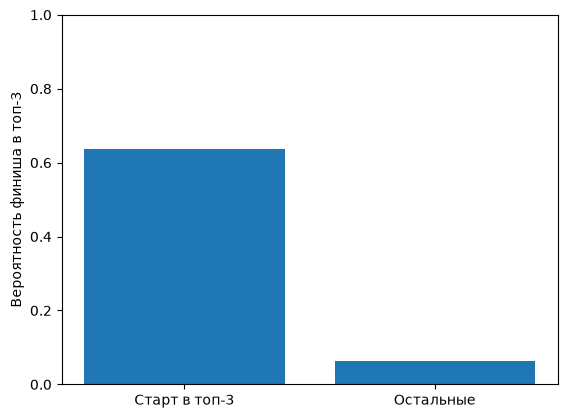

In [12]:
plt.bar(['Старт в топ-3', 'Остальные'], [p1, p2])
plt.ylabel('Вероятность финиша в топ-3')
plt.ylim(0, 1)
plt.show()